In [1]:
import os
import shutil
import torch
import torch.nn as nn #for Section 7
from torch.utils.data import DataLoader
from torch.utils.data import Subset, random_split # For Section 6
from torchvision import datasets, transforms, models
from torch.optim import AdamW #for Section 7
from tqdm import tqdm
from torch.cuda import amp
from torch.utils.data import Dataset
import json
from PIL import Image
from torchvision import datasets, transforms
import kagglehub

#improvement 2: add dynamic learning rate
from torch.optim.lr_scheduler import CosineAnnealingLR # improvement, to dynamically improve learning rate

import matplotlib.pyplot as plt #for section 5
import torchvision.transforms.functional as F # for section #5

#from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns
#from torch.cuda.amp import autocast, GradScaler #for section #7
#change because
#FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
from torch import autocast #for section 7
from torch.amp import GradScaler # for section 7
import numpy as np

# Use current working directory as project root
PROJECT_ROOT = os.getcwd()

# Define the data folder relative to the project root
DATA_DIR = os.path.join(PROJECT_ROOT, "data", "flower_data")
TRAIN_DIR = os.path.join(DATA_DIR, "train")
VALID_DIR = os.path.join(DATA_DIR, "valid")
TEST_DIR  = os.path.join(DATA_DIR, "test")
os.makedirs(DATA_DIR, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

# -------- params (tweak for GPU) ---------- #this is for section 7 #and very useful for SEction 10
# General parameters
NUM_CLASSES = 102 #this one have to upsize to 102 later to fit our full dataset
BATCH_SIZE = 32 #change later to compatible with my rtx3070
ACCUMULATION_STEPS = 4 #change later
NUM_EPOCHS = 100 #Section 10 #change later
LEARNING_RATE = 3e-4 # change later
WEIGHT_DECAY = 1e-4 #change later
NUM_WORKERS = 8 #change later
MODEL_ARCHITECTURE = "Resnet50"


# Save directory for models/checkpoints
SAVE_DIR = os.path.join(PROJECT_ROOT, "checkpoints")
os.makedirs(SAVE_DIR, exist_ok=True)

C:\Users\chuaw\anaconda3\envs\DLSem3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: C:\Users\chuaw\Projects\DLSem3_Assignment1
Data directory: C:\Users\chuaw\Projects\DLSem3_Assignment1\data\flower_data


In [2]:
#identify what device is using, and pass to the next function later, it is fine to use cpu, but optimally better performance will use gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


# Improvement 1 : Add Data Augmentation

In [3]:
# Load cat_to_name mapping
with open(os.path.join(DATA_DIR, "cat_to_name.json"), "r") as f:
    cat_to_name = json.load(f)

# Transforms
transform_train_data = transforms.Compose([
    transforms.RandomRotation(30),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], # this value is not random, check my explaination
                         [0.229, 0.224, 0.225]) # this value is not random...
])
transform_valid_test_data = transforms.Compose([
    transforms.Resize(255), #first make it bigger
    transforms.CenterCrop(224), # and then crop it so that we dont lose data
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], #this will normalize the valid data as well
                         [0.229, 0.224, 0.225])
])
class TestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        # List all image files
        self.image_files = sorted([f for f in os.listdir(root_dir)
                                   if f.lower().endswith(('.png', '.jpg', '.jpeg'))])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        # Return image and filename (no label)
        return image, self.image_files[idx]

# Datasets

# train_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "train"), transform=transform) #this is the old, transform = transform
train_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "train"), transform = transform_train_data)
valid_dataset = datasets.ImageFolder(root=os.path.join(DATA_DIR, "valid"), transform=transform_valid_test_data)
test_dataset = TestDataset(root_dir=os.path.join(DATA_DIR, "test"), transform=transform_valid_test_data)

In [4]:
# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Map numeric labels to class names
def decode_label(label):
    folder_name = train_dataset.classes[label]  # e.g., '1', '2', ...
    return cat_to_name.get(folder_name, folder_name)

# Example
print(f"Number of classes: {len(train_dataset.classes)}")
print(f"First 5 class names: {[decode_label(i) for i in range(5)]}")
print(f"Training samples: {len(train_dataset)}")
print(f"The following is test images")
for images, filenames in test_loader:
    print(filenames)  # shows original file names
    break

Number of classes: 102
First 5 class names: ['pink primrose', 'globe thistle', 'blanket flower', 'trumpet creeper', 'blackberry lily']
Training samples: 6552
The following is test images
('image_00005.jpg', 'image_00006.jpg', 'image_00024.jpg', 'image_00025.jpg', 'image_00029.jpg', 'image_00050.jpg', 'image_00060.jpg', 'image_00065.jpg', 'image_00092.jpg', 'image_00099.jpg', 'image_00114.jpg', 'image_00116.jpg', 'image_00132.jpg', 'image_00176.jpg', 'image_00177.jpg', 'image_00187.jpg', 'image_00191.jpg', 'image_00202.jpg', 'image_00203.jpg', 'image_00204.jpg', 'image_00212.jpg', 'image_00222.jpg', 'image_00239.jpg', 'image_00248.jpg', 'image_00251.jpg', 'image_00258.jpg', 'image_00260.jpg', 'image_00277.jpg', 'image_00282.jpg', 'image_00284.jpg', 'image_00288.jpg', 'image_00291.jpg')


In [5]:
print("Building (ResNet50) model...")
def build_model(num_classes, pretrained=True, freeze_backbone=True):
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    if freeze_backbone:
        for name, param in model.named_parameters():
            if "fc" not in name:
                param.requires_grad = False

    return model.to(device)

Building (ResNet50) model...


In [6]:
# model = build_model(num_classes=NUM_CLASSES, pretrained=True, freeze_backbone=True)
# print(model)
# print("Model Built Sucessfully lets go!")

In [7]:
# need to add this to dynamically adjust learning rate
criterion = nn.CrossEntropyLoss()
# optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

# Mixed precision scaler
scaler = GradScaler()

In [8]:
try:
    X_batch, y_batch = next(iter(train_loader))

    # Move the data to your GPU (since your model is on the GPU)
    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    # --- This is the Forward Pass ---
    # Get the model's predictions for the batch
    outputs = model(X_batch)

    print("Lets goooo Sanity successful!")
    print(f"Input batch shape: {X_batch.shape}")
    print(f"Output (predictions) shape: {outputs.shape}")
    print(f"COrrect output, The output shape is [Batch Size, Number of Classes] -> [{BATCH_SIZE}, {NUM_CLASSES}].")

except Exception as e:
    print(f"Sanity Check, error occured at: {e}")

Sanity Check, error occured at: name 'model' is not defined


In [9]:
# --- Define your model, optimizer, and scheduler structures first ---
model = build_model(num_classes=NUM_CLASSES, freeze_backbone=True)
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

# --- Load the checkpoint OR initialize for a fresh start ---
CHECKPOINT_FILENAME = 'best_model_checkpoint_fresh.pth'
try:
    print(f"--- Loading checkpoint: {CHECKPOINT_FILENAME} ---")
    checkpoint = torch.load(CHECKPOINT_FILENAME)

    # Load model and optimizer states
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    # Load the training progress
    start_epoch = checkpoint['epoch']
    best_val_accuracy = checkpoint['best_val_accuracy']
    history = checkpoint['history'] # <-- THIS IS THE KEY! It loads your old results.

    # Fast-forward the scheduler to the correct state
    scheduler.last_epoch = start_epoch

    print(f"Resuming training from epoch {start_epoch + 1}")
    print(f"Best accuracy so far: {best_val_accuracy:.2f}%")

except FileNotFoundError:
    print("--- No checkpoint found, starting training from scratch ---")
    start_epoch = 0
    best_val_accuracy = 0.0
    # Initialize a new history dictionary if starting fresh
    history = {
        'train_loss': [],
        'val_loss': [],
        'val_acc': [],
        'train_acc': [],      # ADD THIS - to store training accuracy
        'learning_rate': []
    }

#dictionary to store our hyperparametersss
HPARAMS = {
    'learning_rate': LEARNING_RATE,
    'epochs': NUM_EPOCHS,
    'batch_size': BATCH_SIZE,
    'accumulation_steps': ACCUMULATION_STEPS,
    'weight_decay': WEIGHT_DECAY,
    'architecture': MODEL_ARCHITECTURE,
    'num_workers' : NUM_WORKERS
}

for epoch in range(start_epoch, NUM_EPOCHS):
    model.train() # put model in training mode
    train_loss = 0.0 #Check definition later, dont understand why this is for

    # ✨ ADD THESE - to track training accuracy for the epoch
    train_correct = 0
    train_total = 0

    #Progress bar to show when running
    # YOUR ASSISTANT'S NOTE: Added enumerate() to get the batch index 'i'. This fixes the crash.
    train_loop = tqdm(enumerate(train_loader), total=len(train_loader), leave=True)
    train_loop.set_description(f"Epoch {epoch+1}/{NUM_EPOCHS} [Training]")

    # YOUR ASSISTANT'S NOTE: Clear gradients ONCE before the accumulation cycle begins.
    optimizer.zero_grad()

    # YOUR ASSISTANT'S NOTE: The loop now correctly provides the index 'i' and the batch.
    for i, (X_batch, y_batch) in train_loop:
        # now this will pass the training batch to your device, device is automatically determine
        # above, CPU for cpu, and cuda for GPU, optimally, gpu will be way more faster, i am using
        # gpu
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        #1 forward pass
        # i think this is the same as model.fit(X_train), but i am not sure, probably tensor doesnt need fit
        outputs = model(X_batch)

        #2 Calculate loss
        loss = criterion(outputs, y_batch)

        # ✨ ADD THIS - to calculate training accuracy for the current batch
        _, predicted = torch.max(outputs.data, 1)
        train_total += y_batch.size(0)
        train_correct += (predicted == y_batch).sum().item()

        loss = loss / ACCUMULATION_STEPS # this is to utilize our accumulation steps

        #3 Backward pass
        # YOUR ASSISTANT'S NOTE: This call now SUMS the gradients because we haven't cleared them yet.
        loss.backward()

        # THIS IS THE IMPORTANT LINE THAT WAS MISSING
        train_loss += loss.item() * ACCUMULATION_STEPS

        # YOUR ASSISTANT'S NOTE: The optimizer only steps and clears gradients here, after enough batches.
        # The incorrect calls from before have been REMOVED.
        if (i + 1) % ACCUMULATION_STEPS == 0:
            optimizer.step()
            optimizer.zero_grad()

    # ✨ ADD THIS - to calculate the final training accuracy for the epoch
    train_accuracy = 100 * train_correct / train_total

    #4 Validation
    model.eval()   # eval for evaluation ,this put the model into evaluation mode
    valid_loss = 0.0
    correct = 0
    total = 0

    # validation progress bar
    val_loop = tqdm(valid_loader, leave=True)
    val_loop.set_description(f"Epoch {epoch+1}/{NUM_EPOCHS} [Validation]")

    # dont need to calculate gradient during validation
    #but why?
    with torch.no_grad():
        for X_batch, y_batch in val_loop:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            valid_loss += loss.item()

            # Calculate accuracy
            _, predicted = torch.max(outputs.data, 1)
            total += y_batch.size(0)
            correct += (predicted == y_batch).sum().item()

    # It must run AFTER the validation loop (above) is finished, not inside it.

    # Print Epoch Statistics
    avg_train_loss = train_loss / len(train_loader)
    avg_valid_loss = valid_loss / len(valid_loader)
    accuracy = 100 * correct / total
    #This will let me get the current learning rate from the optimizer
    current_lr = optimizer.param_groups[0]['lr']

    
    print(f"\nEpoch {epoch+1} Summary:")
    print(f"  -> Training Loss: {avg_train_loss:.4f}   | Training Accuracy: {train_accuracy:.2f}%")
    print(f"  -> Validation Loss: {avg_valid_loss:.4f} | Validation Accuracy: {accuracy:.2f}%")
    print(f"  -> Current Learning Rate: {current_lr:.6f}\n")

    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_valid_loss)
    history['val_acc'].append(accuracy)
    history['train_acc'].append(train_accuracy) 
    history['learning_rate'].append(current_lr)

    scheduler.step()#Improvement2 : update the learning rate dynamically

    if accuracy > best_val_accuracy:
        best_val_accuracy = accuracy

        # Create a checkpoint dictionary
        checkpoint = {
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_accuracy': best_val_accuracy,
            'hyperparameters': HPARAMS,
            'history': history, # This will Save the history so far
            'class_to_idx': train_dataset.class_to_idx, # This will Save the class mapping
            'cat_to_name': cat_to_name # and this will sav the name mapping
        }

        # Save the checkpoint
        torch.save(checkpoint, CHECKPOINT_FILENAME)

        print(f"huhu ! Checkpoint saved at epoch {epoch + 1} with new best accuracy: {best_val_accuracy:.2f}%")

print("The training is successfully completed")

C:\Users\chuaw\AppData\Local\Temp\ipykernel_13156\1541441583.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_FILENAME)


--- Loading checkpoint: best_model_checkpoint_fresh.pth ---
--- No checkpoint found, starting training from scratch ---


Epoch 1/100 [Validation]: 100%|████████████████████████████████████████████████████████| 26/26 [00:07<00:00,  3.68it/s]



Epoch 1 Summary:
  -> Training Loss: 4.3259   | Training Accuracy: 9.42%
  -> Validation Loss: 4.0112 | Validation Accuracy: 16.01%
  -> Current Learning Rate: 0.000300

huhu ! Checkpoint saved at epoch 1 with new best accuracy: 16.01%


Epoch 2/100 [Validation]: 100%|████████████████████████████████████████████████████████| 26/26 [00:06<00:00,  3.75it/s]



Epoch 2 Summary:
  -> Training Loss: 3.8538   | Training Accuracy: 21.93%
  -> Validation Loss: 3.6035 | Validation Accuracy: 34.84%
  -> Current Learning Rate: 0.000300

huhu ! Checkpoint saved at epoch 2 with new best accuracy: 34.84%


... (192 outputs left out)

Epoch 99/100 [Validation]: 100%|███████████████████████████████████████████████████████| 26/26 [00:06<00:00,  4.01it/s]



Epoch 99 Summary:
  -> Training Loss: 0.5676   | Training Accuracy: 89.93%
  -> Validation Loss: 0.3658 | Validation Accuracy: 94.62%
  -> Current Learning Rate: 0.000001



Epoch 100/100 [Validation]: 100%|██████████████████████████████████████████████████████| 26/26 [00:06<00:00,  3.95it/s]


Epoch 100 Summary:
  -> Training Loss: 0.5657   | Training Accuracy: 90.31%
  -> Validation Loss: 0.3845 | Validation Accuracy: 94.74%
  -> Current Learning Rate: 0.000001

The training is successfully completed


--- Loading checkpoint: best_model_checkpoint_fresh.pth ---
Successfully loaded history. Best validation accuracy was 95.11%.

--- Saving training history to CSV ---
Training history saved to training_log_fresh.csv



C:\Users\chuaw\AppData\Local\Temp\ipykernel_13156\2606431582.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_FILENAME)


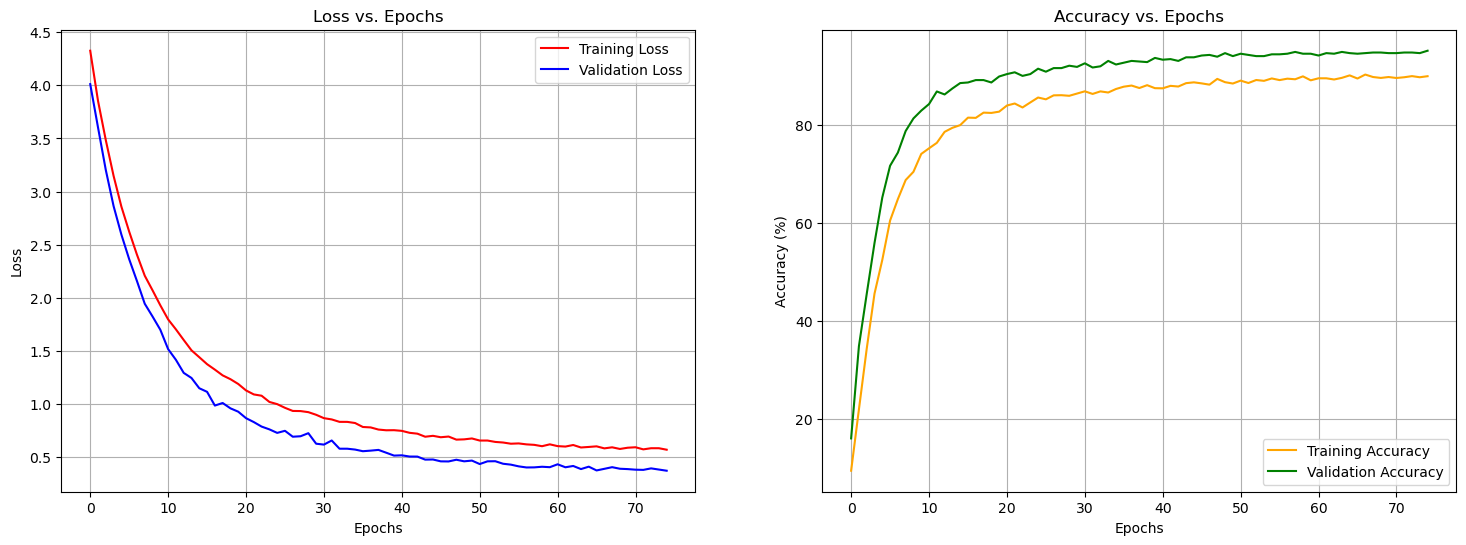

--- Generating confusion matrix ---


Predicting on validation set: 100%|████████████████████████████████████████████████████| 26/26 [00:06<00:00,  4.15it/s]



Confusion matrix saved as confusion_matrix_fresh.png


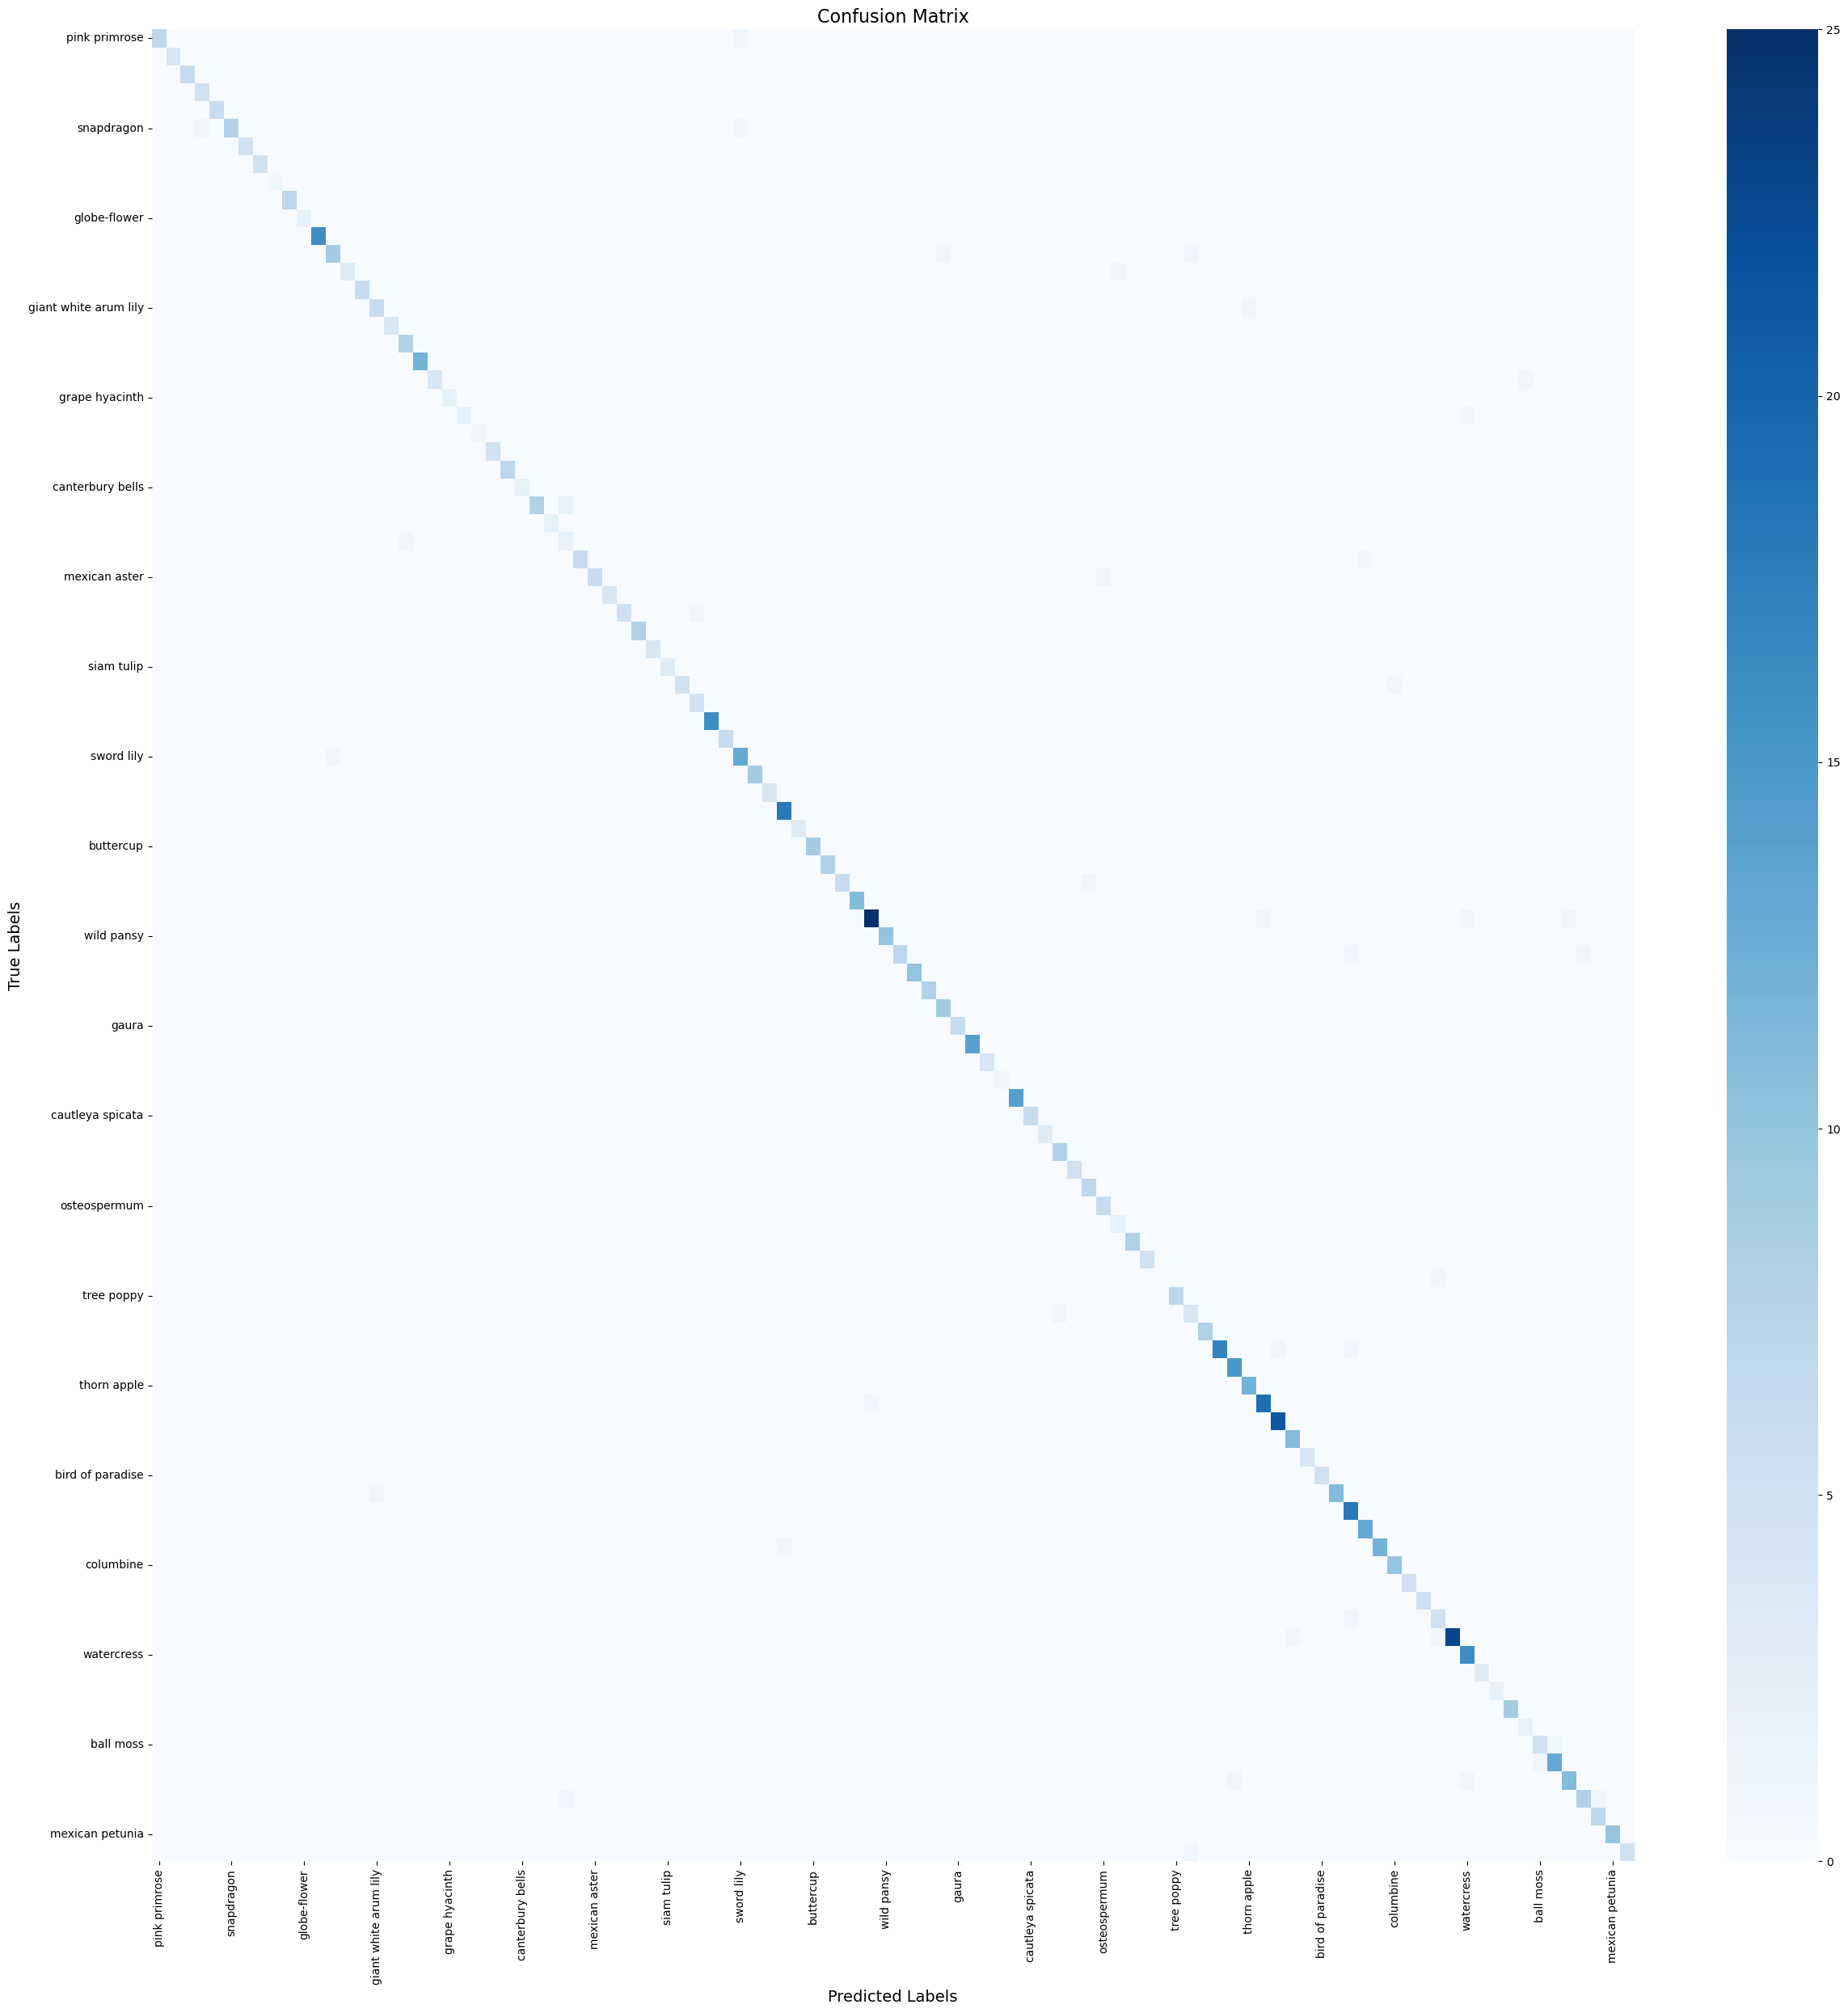

In [15]:
import pandas as pd
CHECKPOINT_FILENAME = 'best_model_checkpoint_fresh.pth'

try:
    # --- 1. Load the Entire Checkpoint ---
    print(f"--- Loading checkpoint: {CHECKPOINT_FILENAME} ---")
    checkpoint = torch.load(CHECKPOINT_FILENAME)
    
    # --- 2. Extract History and Hyperparameters from the Checkpoint ---
    history = checkpoint['history']
    hparams = checkpoint['hyperparameters']
    best_acc = checkpoint['best_val_accuracy']
    
    print(f"Successfully loaded history. Best validation accuracy was {best_acc:.2f}%.")

    # --- 3. Save Training History to CSV ---
    print("\n--- Saving training history to CSV ---")
    history_df = pd.DataFrame(history)
    history_df['epoch'] = range(1, len(history_df) + 1)
    history_df = history_df[['epoch', 'train_loss', 'val_loss', 'val_acc', 'learning_rate']]
    
    log_filename = "training_log_fresh.csv"
    history_df.to_csv(log_filename, index=False)
    print(f"Training history saved to {log_filename}\n")

    # --- 4. Plot the Training History ---
    plot_training_history(history) # Assuming your plotting function is defined in a previous cell

    # --- 5. Generate and Plot Confusion Matrix ---
    print("--- Generating confusion matrix ---")
    model = build_model(num_classes=NUM_CLASSES, freeze_backbone=False) # Re-create model structure
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval()

    all_preds = []
    all_labels = []
    with torch.no_grad():
        for images, labels in tqdm(valid_loader, desc="Predicting on validation set"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)
    class_names = valid_dataset.classes
    readable_names = [cat_to_name.get(name, name) for name in class_names]

    plt.figure(figsize=(25, 25))
    sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=False, yticklabels=False)
    plt.xlabel("Predicted Labels", fontsize=14)
    plt.ylabel("True Labels", fontsize=14)
    plt.title("Confusion Matrix", fontsize=16)

    tick_spacing = 5
    plt.xticks(
        ticks=np.arange(len(readable_names))[::tick_spacing] + 0.5,
        labels=readable_names[::tick_spacing], rotation=90, ha='center'
    )
    plt.yticks(
        ticks=np.arange(len(readable_names))[::tick_spacing] + 0.5,
        labels=readable_names[::tick_spacing], rotation=0, va='center'
    )
    plt.tight_layout()
    plt.savefig("confusion_matrix_fresh.png")
    print("\nConfusion matrix saved as confusion_matrix_fresh.png")
    plt.show()

except FileNotFoundError:
    print(f"\nERROR: Checkpoint file '{CHECKPOINT_FILENAME}' not found.")
    print("Please make sure you have successfully completed the training loop cell first.")
except Exception as e:
    print(f"\nAn error occurred: {e}")

In [11]:
# print("--- Saving training history ---")
# try:
#     # This will create a DataFrame from the history dictionary
#     historyDF = pd.DataFrame(history)
#     historyDF['epoch'] = range(1, len(historyDF) + 1) # Add an epoch column

#     # Reorder columns to make epoch the first column
#     historyDF = historyDF[['epoch', 'train_loss', 'val_loss', 'val_acc', 'learning_rate']]

#     # Save to a CSV file
#     log_filename = "training_log.csv"
#     historyDF.to_csv(log_filename, index=False)
#     print(f"Training history saved to {log_filename}\n")

# except NameError:
#     print("Could not save history: 'history' dictionary not found.")
#     print("Please make sure you have run the training loop cell first.\n")

In [12]:
# --- 2. Generate and Plot Confusion Matrix ---
print("--- Generating confusion matrix ---")
try:
    # Load the best model checkpoint
    # Note: Ensure the model architecture is defined (run the build_model cell first)
    model = build_model(num_classes=NUM_CLASSES, freeze_backbone=False)
    checkpoint = torch.load(BEST_MODEL_CHECKPOINT_NAME)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.to(device)
    model.eval() # Set the model to evaluation mode

    all_preds = []
    all_labels = []

    # No need to calculate gradients for this part
    with torch.no_grad():
        for images, labels in tqdm(valid_loader, desc="Predicting on validation set"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Create the confusion matrix using scikit-learn
    cm = confusion_matrix(all_labels, all_preds)

    # Get class names for labeling the plot
    class_names = valid_dataset.classes
    readable_names = [cat_to_name.get(name, name) for name in class_names]

    # Plot the confusion matrix using seaborn
    plt.figure(figsize=(25, 25))
    sns.heatmap(cm, annot=False, cmap='Blues', xticklabels=False, yticklabels=False)
    plt.xlabel("Predicted Labels", fontsize=14)
    plt.ylabel("True Labels", fontsize=14)
    plt.title("Confusion Matrix", fontsize=16)

    # To make labels more readable on a large matrix, show every 5th label
    tick_spacing = 5
    plt.xticks(
        ticks=np.arange(len(readable_names))[::tick_spacing] + 0.5,
        labels=readable_names[::tick_spacing],
        rotation=90,
        ha='center'
    )
    plt.yticks(
        ticks=np.arange(len(readable_names))[::tick_spacing] + 0.5,
        labels=readable_names[::tick_spacing],
        rotation=0,
        va='center'
    )

    plt.tight_layout()
    plt.savefig("confusion_matrix.png")
    print("\nConfusion matrix saved as confusion_matrix.png")
    plt.show()

except FileNotFoundError:
    print("\nCould not generate confusion matrix: 'best_model_checkpoint.pth' not found.")
    print("Please make sure you have successfully completed at least one epoch of training.")
except NameError as e:
    print(f"\nAn error occurred: {e}")
    print("Please ensure all necessary variables (like 'valid_loader', 'cat_to_name', etc.) are defined.")

--- Generating confusion matrix ---

An error occurred: name 'BEST_MODEL_CHECKPOINT_NAME' is not defined
Please ensure all necessary variables (like 'valid_loader', 'cat_to_name', etc.) are defined.


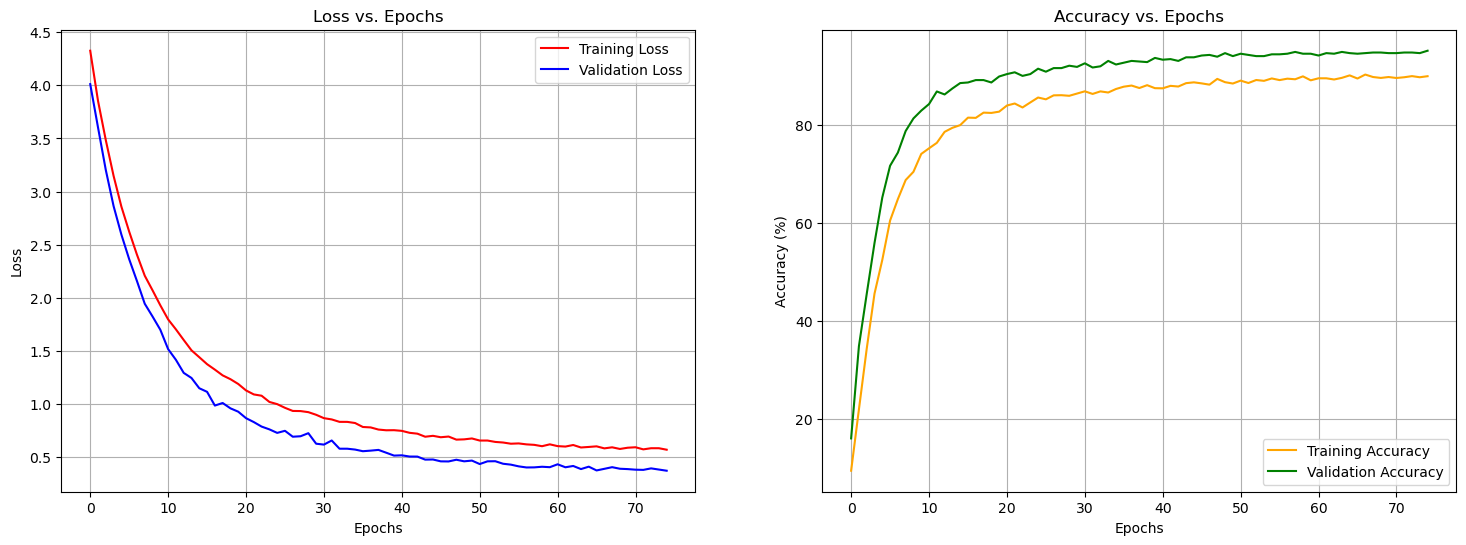

In [13]:
def plot_training_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

    # this one will plot training and valid loss
    ax1.plot(history['train_loss'], label='Training Loss', color='red')
    ax1.plot(history['val_loss'], label='Validation Loss', color='blue')
    ax1.set_title('Loss vs. Epochs')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)

    # ✨ this one will now plot both training and validation accuracy
    ax2.plot(history['train_acc'], label='Training Accuracy', color='orange') # ✨ ADD THIS
    ax2.plot(history['val_acc'], label='Validation Accuracy', color='green')
    ax2.set_title('Accuracy vs. Epochs')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(True)

    plt.show()

# Now when you call this function, it will show both accuracy lines
plot_training_history(history)